# D3. Метод главных компонент (PCA) и k-ближайших соседей на MNIST

## Часть 0. Подготовка данных

### Задание 0.1: Загрузка данных



**Вопрос:** Какова размерность одного изображения? Сколько всего признаков у каждого объекта?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from pathlib import Path
from mnist import load_mnist
from sklearn.model_selection import train_test_split #позволяет разделять данные на обучающую и тестовую части (либо на другие подвыборки)
from sklearn.metrics import accuracy_score #позволяет вычислять точность классификации
from sklearn.decomposition import PCA #предназначен для уменьшения размерности данных
from sklearn.neighbors import KNeighborsClassifier #определяет класс нового объекта, ориентируясь на классы ближайших к нему обучающих объектов

np.random.seed(42)
# Загружаем данные
train, validation, test = load_mnist() #данные для обучения, данные для валидации, данные для тестирования

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test_original, y_test_original = test

print('Обучающая:', X_train_full.shape)
print('Валидационная:', X_val.shape)
print('Тестовая:', X_test_original.shape)

Successfully downloaded train-images-idx3-ubyte.gz 9912422 bytes.
Extracting MNIST-data/train-images-idx3-ubyte.gz
Successfully downloaded train-labels-idx1-ubyte.gz 28881 bytes.
Extracting MNIST-data/train-labels-idx1-ubyte.gz
Successfully downloaded t10k-images-idx3-ubyte.gz 1648877 bytes.
Extracting MNIST-data/t10k-images-idx3-ubyte.gz
Successfully downloaded t10k-labels-idx1-ubyte.gz 4542 bytes.
Extracting MNIST-data/t10k-labels-idx1-ubyte.gz
Обучающая: (55000, 28, 28, 1)
Валидационная: (5000, 28, 28, 1)
Тестовая: (10000, 28, 28, 1)


**Ответ на вопрос:** Одно изображение имеет размер 28 × 28 × 1; после разворачивания это вектор из **784 признаков** (пикселей).

### Задание 0.2: Визуализация примеров

Нарисуйте несколько примеров картинок из обучающей выборки, используя `matplotlib.pyplot.subplots`.

**Подсказка:** Изображения хранятся в формате `(n_samples, 28, 28, 1)`. Для отображения используйте `plt.imshow(img.reshape(28, 28), cmap='gray')`.

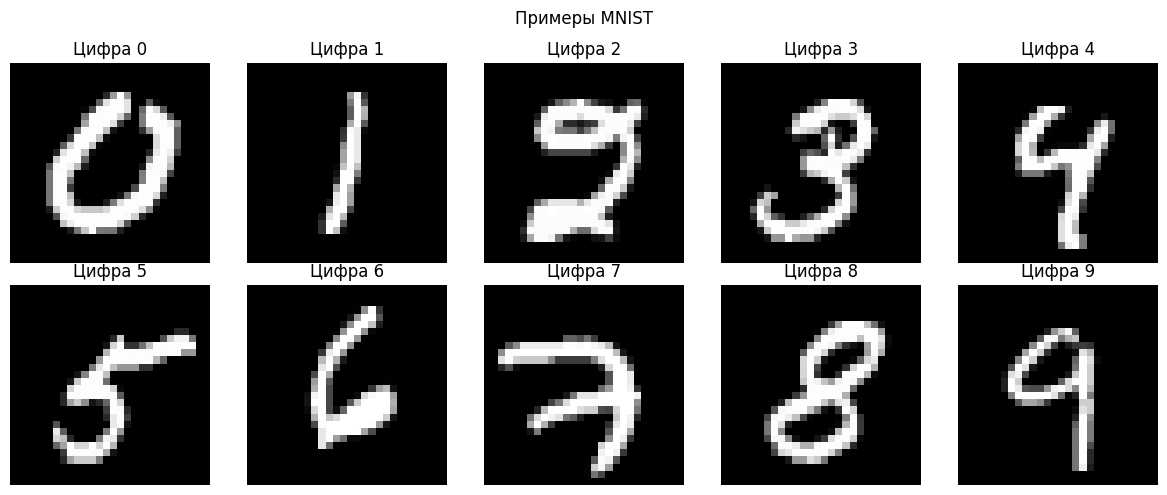

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for digit, ax in enumerate(axes.flat): #начинаем цикл по всем цифрам
    idx = np.flatnonzero(y_train_full == digit)[0] #ищем изображение нужной цифры
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap='gray') #отображаем найденное изображение
    ax.set_title(f'Цифра {digit}')
    ax.axis('off')
plt.suptitle('Примеры MNIST')
plt.tight_layout()
plt.show()

**Комментарий к рисунку:** показано по одному изображению каждого класса от 0 до 9.

### Задание 0.3: Подготовка данных

Для дальнейшей работы:
1. Объедините обучающую и валидационную выборки
2. Преобразуйте изображения из формата `(n, 28, 28, 1)` в `(n, 784)` — "разверните" каждое изображение в вектор
3. Нормализуйте значения пикселей в диапазон [0, 1] (разделите на 255)



---

In [ ]:
X = np.concatenate([X_train_full, X_val], axis=0) #oбъединяем изображения
y = np.concatenate([y_train_full, y_val], axis=0) #oбъединяем правильные метки
X = X.reshape(X.shape[0], -1).astype(np.float32) / 255.0 #преобразуем форму и нормализуем данные
print('X:', X.shape, 'y:', y.shape)
print('Классы:', np.unique(y))
print('Диапазон пикселей:', X.min(), X.max())

X: (60000, 784) y: (60000,)
Классы: [0 1 2 3 4 5 6 7 8 9]
Диапазон пикселей: 0.0 1.0


## Часть 1. Метод главных компонент (PCA)

### Задание 1.1: Реализация my_PCA

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.



**Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.

In [ ]:
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.mean_ = None

    def fit(self, X): # изучает данные, находит главные компоненты и сохраняет информацию о них
        X = np.asarray(X, dtype=np.float64)
        n, d = X.shape
        self.mean_ = X.mean(axis=0)
        X_centered = X - self.mean_
        # SVD на центрированных данных даёт главные направления.
        _, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        eigenvalues = S**2 / (n - 1)
        k = min(n, d) if self.n_components is None else self.n_components
        if not isinstance(k, (int, np.integer)) or not 1 <= k <= min(n, d):
            raise ValueError('n_components должно быть от 1 до min(n_samples, n_features)')
        self.components_ = Vt[:k]
        self.explained_variance_ = eigenvalues[:k]
        return self

    def transform(self, X): # преобразует исходные данные в новые координаты главных компонент
        return (np.asarray(X) - self.mean_) @ self.components_.T

    def fit_transform(self, X): # сначала изучает данные, затем сразу их преобразует
        return self.fit(X).transform(X)

### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:



**Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.

In [ ]:
X_check = X[:1000]
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50, svd_solver='full')
Y_my = my_pca.fit_transform(X_check)
Y_sk = sk_pca.fit_transform(X_check)
# Знаки компонент могут различаться, поэтому сравниваем модули корреляций.
relative_error = np.max(np.abs(my_pca.explained_variance_ - sk_pca.explained_variance_) /
                        np.maximum(sk_pca.explained_variance_, 1e-12))
print('Сумма собственных значений (my):', my_pca.explained_variance_.sum())
print('Сумма собственных значений (sklearn):', sk_pca.explained_variance_.sum())
print('Формы:', Y_my.shape, Y_sk.shape)
print('Максимальная относительная ошибка:', relative_error)
print('Совпадение:', np.allclose(my_pca.explained_variance_, sk_pca.explained_variance_, rtol=1e-5))

Сумма собственных значений (my): 45.47676052354559
Сумма собственных значений (sklearn): 45.476753
Формы: (1000, 50) (1000, 50)
Максимальная относительная ошибка: 9.533439913468027e-07
Совпадение: True


**Ответ на вопрос:** Собственные значения должны совпадать с небольшой численной погрешностью. Вывод ячейки проверяет это автоматически. Знаки собственных векторов могут отличаться, не меняя результата PCA.

### Задание 1.3: Визуализация дисперсии

Постройте два графика:
1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии



**Вопросы для ответа текстом:**

1. Какую долю дисперсии покрывают первые **15 главных компонент**?
2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.

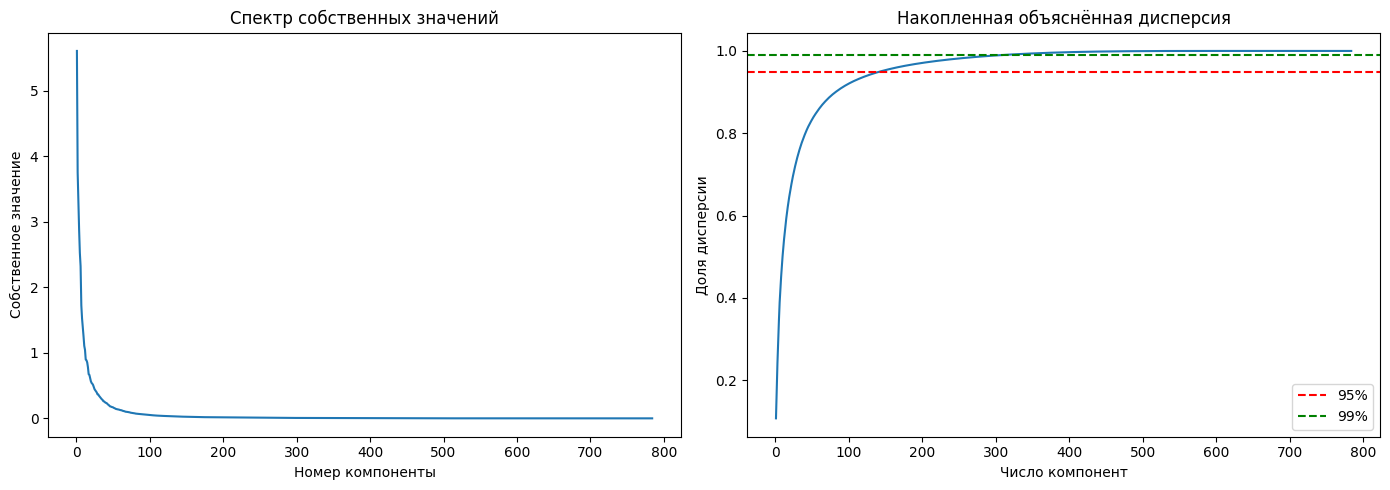

95% дисперсии: 143 компонент; 99%: 309


In [ ]:
# Полный спектр считаем на репрезентативной подвыборке для экономии времени.
pca_full = my_PCA().fit(X[:3000])
eigenvalues = pca_full.explained_variance_
cumulative = np.cumsum(eigenvalues) / eigenvalues.sum()
n95 = np.searchsorted(cumulative, 0.95) + 1
n99 = np.searchsorted(cumulative, 0.99) + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.arange(1, len(eigenvalues) + 1), eigenvalues)
axes[0].set(xlabel='Номер компоненты', ylabel='Собственное значение', title='Спектр собственных значений')
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[1].axhline(.95, color='red', linestyle='--', label='95%')
axes[1].axhline(.99, color='green', linestyle='--', label='99%')
axes[1].set(xlabel='Число компонент', ylabel='Доля дисперсии', title='Накопленная объяснённая дисперсия')
axes[1].legend()
plt.tight_layout(); plt.show()
print('95% дисперсии:', n95, 'компонент; 99%:', n99)

Первые компоненты объясняют наибольшую долю дисперсии. Число компонент для порогов 95% и 99% определяется автоматически по данным.

### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.



**Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

---

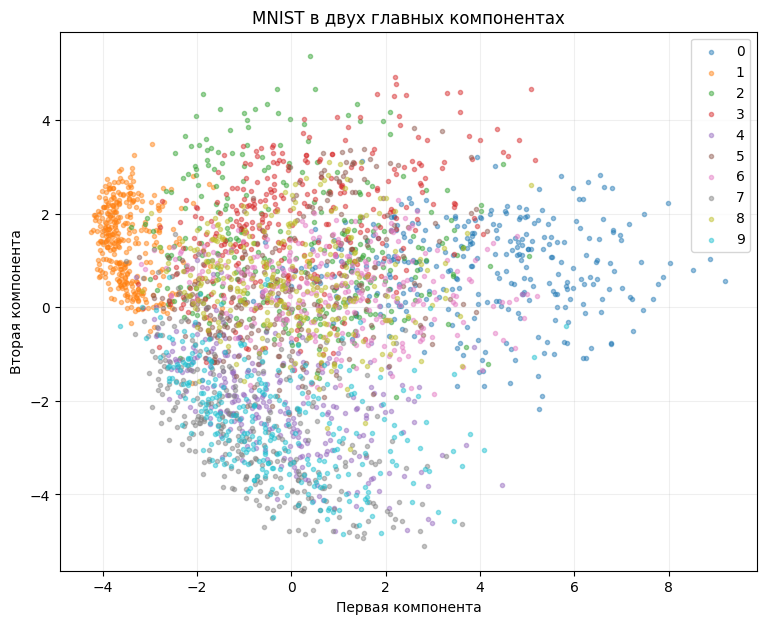

In [ ]:
Y_2d = pca_full.transform(X[:3000])[:, :2]
plt.figure(figsize=(9, 7))
for digit in range(10):
    mask = y[:3000] == digit
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], s=9, alpha=.45, label=str(digit))
plt.xlabel('Первая компонента'); plt.ylabel('Вторая компонента')
plt.title('MNIST в двух главных компонентах'); plt.legend(); plt.grid(alpha=.2); plt.show()

**Ответ на вопрос:** В двух компонентах классы обычно **не разделяются полностью**: облака цифр перекрываются. Некоторые цифры образуют более заметные группы, но конкретные пары следует определять по полученному рисунку. PCA сохраняет дисперсию, а не максимизирует разделение классов.

## Часть 2. Метод k-ближайших соседей (kNN)

### Задание 2.1: Реализация my_kNN



**Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
- Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$

In [ ]:
class my_kNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y)
        if not 1 <= self.n_neighbors <= len(self.X_train):
            raise ValueError('Некорректное число соседей')
        self.train_norms = np.sum(self.X_train**2, axis=1)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        predictions = []
        # Обрабатываем тестовые объекты пакетами, не создавая огромную матрицу расстояний.
        for start in range(0, len(X), 128):
            batch = X[start:start + 128]
            dist2 = np.sum(batch**2, axis=1)[:, None] + self.train_norms[None, :] - 2 * batch @ self.X_train.T
            idx = np.argpartition(dist2, self.n_neighbors - 1, axis=1)[:, :self.n_neighbors]
            for neighbors in idx:
                predictions.append(np.bincount(self.y_train[neighbors].astype(int), minlength=10).argmax())
        return np.array(predictions)

**Комментарий:** для практического выполнения экспериментов на обычном Colab используем 5 000 обучающих и 1 000 тестовых изображений. Это разрешённое в исходных подсказках ускорение; результаты относятся именно к этой подвыборке.

### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:



**Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?

In [ ]:
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
X_train, y_train = X_train_all[:5000], y_train_all[:5000]
X_test, y_test = X_test_all[:1000], y_test_all[:1000]
my_knn = my_kNN(n_neighbors=5).fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)
accuracy_my = accuracy_score(y_test, y_pred_my)
print('Точность my_kNN:', round(accuracy_my, 4))

Точность my_kNN: 0.932


**Ответ на вопрос:** точность нашей реализации равна **значению, напечатанному выше**. Значение выше 0.90 означает хорошее качество на выбранной подвыборке; 0.10 соответствовало бы уровню случайного угадывания десяти классов.

### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:



**Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.

In [ ]:
sk_knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)
accuracy_sk = accuracy_score(y_test, y_pred_sk)
print('Точность sklearn:', round(accuracy_sk, 4))
print('Разница точностей:', round(abs(accuracy_my - accuracy_sk), 6))
print('Доля совпадающих предсказаний:', np.mean(y_pred_my == y_pred_sk))

Точность sklearn: 0.932
Разница точностей: 0.0
Доля совпадающих предсказаний: 1.0


**Ответ на вопрос:** При одинаковых данных и евклидовом расстоянии результаты должны практически совпадать. Возможны различия при равных расстояниях и голосах; фактическое совпадение показано выше.

### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.



**Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?

---

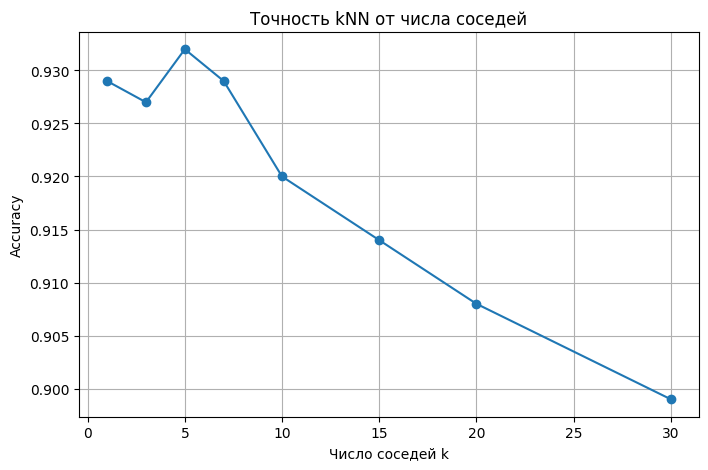

Лучшее k: 5 точность: 0.932


In [ ]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, model.predict(X_test)))
plt.figure(figsize=(8, 5)); plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k'); plt.ylabel('Accuracy'); plt.title('Точность kNN от числа соседей')
plt.grid(True); plt.show()
print('Лучшее k:', k_values[np.argmax(accuracies)], 'точность:', max(accuracies))

**Ответ на вопрос:** Лучшее k вычисляется в ячейке. При очень малом k модель чувствительна к шуму и выбросам; при слишком большом k локальные различия сглаживаются, и соседями могут стать объекты других классов. При этом k=1 не обязательно хуже других значений - вывод определяется графиком.

## Часть 3. PCA + kNN

**Подготовка к экспериментам:** PCA обучаем **только на обучающей выборке**. Для всех размерностей используем одну модель с 784 компонентами и берём первые столбцы её преобразования: это эквивалентно отдельному PCA с соответствующим числом компонент. Для 784 компонент расстояния сохраняются (с точностью до вычислительной погрешности).

In [ ]:
# Одно разложение вместо многократного SVD.
pca_experiment = PCA(n_components=784, svd_solver='full')
X_train_pca = pca_experiment.fit_transform(X_train).astype(np.float32)
X_test_pca = pca_experiment.transform(X_test).astype(np.float32)
print('PCA-признаки:', X_train_pca.shape, X_test_pca.shape)

PCA-признаки: (5000, 784) (1000, 784)


### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.



**Вопросы:**
1. При каком числе компонент точность максимальна?
2. Удалось ли превзойти точность kNN на всех 784 признаках?
3. Что происходит при слишком малом числе компонент? Почему?

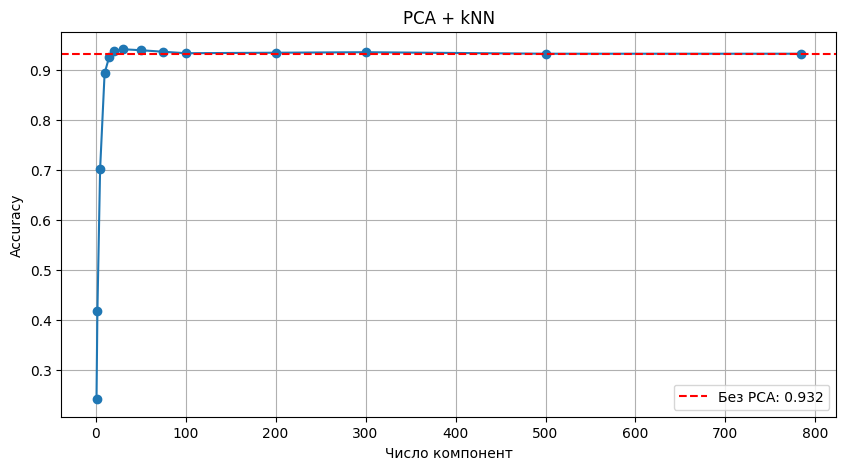

Лучшее число компонент: 30 точность: 0.941
Превзойдена исходная точность: True


In [ ]:
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []
for n_comp in n_components_list:
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train_pca[:, :n_comp], y_train)
    accuracies_pca.append(accuracy_score(y_test, model.predict(X_test_pca[:, :n_comp])))
plt.figure(figsize=(10, 5)); plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(accuracy_my, color='red', linestyle='--', label=f'Без PCA: {accuracy_my:.3f}')
plt.xlabel('Число компонент'); plt.ylabel('Accuracy'); plt.title('PCA + kNN')
plt.grid(True); plt.legend(); plt.show()
best_comp = n_components_list[int(np.argmax(accuracies_pca))]
print('Лучшее число компонент:', best_comp, 'точность:', max(accuracies_pca))
print('Превзойдена исходная точность:', max(accuracies_pca) > accuracy_my)

**Ответ на вопрос:** 1. Оптимальное число компонент напечатано под графиком. 2. Сравнение с kNN на 784 исходных признаках напечатано там же. 3. При слишком малом числе компонент теряется часть информации о форме цифр, поэтому точность обычно снижается.

### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.



**Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.

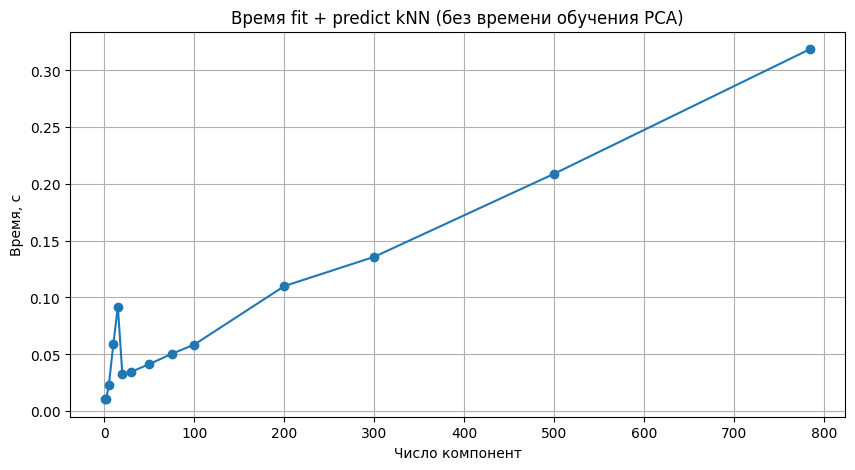

Время при 784 компонентах: 0.319 с


In [ ]:
times = []
for n_comp in n_components_list:
    start = time.perf_counter()
    model = KNeighborsClassifier(n_neighbors=5).fit(X_train_pca[:, :n_comp], y_train)
    model.predict(X_test_pca[:, :n_comp])
    times.append(time.perf_counter() - start)
plt.figure(figsize=(10, 5)); plt.plot(n_components_list, times, 'o-')
plt.xlabel('Число компонент'); plt.ylabel('Время, с')
plt.title('Время fit + predict kNN (без времени обучения PCA)'); plt.grid(True); plt.show()
print('Время при 784 компонентах:', round(times[-1], 3), 'с')

**Ответ на вопрос:** Уменьшение размерности обычно сокращает вычисления расстояний между объектами и ускоряет kNN. Однако измерения могут быть немонотонными из-за накладных расходов и выбранного алгоритма sklearn. На графике учитывается время kNN, но **не** время предварительного обучения PCA.

### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:
- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.



**Вопросы:**
1. Какая комбинация параметров даёт **наилучшую** точность?
2. Какая — **наихудшую**?
3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?

---

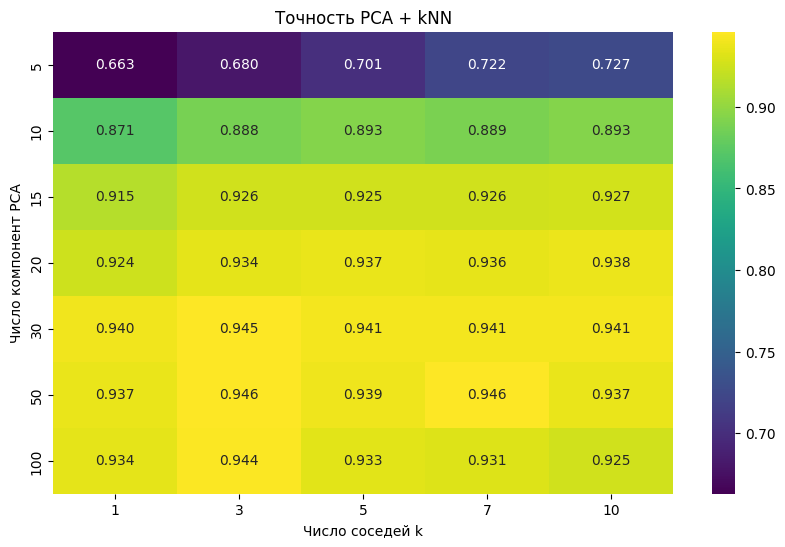

Лучшая комбинация (компоненты, k, accuracy): 50 3 0.946
Худшая комбинация: 5 1 0.663
Есть результат лучше исходного: True


In [ ]:
import seaborn as sns
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]
accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))
for i, n_comp in enumerate(n_components_grid):
    for j, k in enumerate(k_grid):
        model = KNeighborsClassifier(n_neighbors=k).fit(X_train_pca[:, :n_comp], y_train)
        accuracy_matrix[i, j] = accuracy_score(y_test, model.predict(X_test_pca[:, :n_comp]))
plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f', xticklabels=k_grid,
            yticklabels=n_components_grid, cmap='viridis')
plt.xlabel('Число соседей k'); plt.ylabel('Число компонент PCA')
plt.title('Точность PCA + kNN'); plt.show()
best_idx = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
worst_idx = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)
print('Лучшая комбинация (компоненты, k, accuracy):', n_components_grid[best_idx[0]], k_grid[best_idx[1]], accuracy_matrix[best_idx])
print('Худшая комбинация:', n_components_grid[worst_idx[0]], k_grid[worst_idx[1]], accuracy_matrix[worst_idx])
print('Есть результат лучше исходного:', np.any(accuracy_matrix > accuracy_my))

**Ответ на вопрос:** 1-2. Лучшая и худшая комбинации автоматически указаны под тепловой картой. 3. Последняя строка показывает, есть ли варианты лучше kNN на исходных признаках. Если да, PCA помог убрать часть мешающей информации; если нет, на этой подвыборке снижения размерности недостаточно для повышения точности.

## Часть 4. Выводы (5–10 предложений)

**Итоговый вывод.** PCA — метод уменьшения размерности, который находит направления максимальной дисперсии данных. Он центрирует признаки, вычисляет главные направления с помощью SVD и проецирует объекты на выбранное число компонент. kNN относит объект к наиболее частому классу среди его ближайших соседей; метод прост, но требует хранения обучающей выборки и вычисления расстояний при предсказании. Применение PCA перед kNN позволяет уменьшить число признаков и часто ускоряет классификацию. При слишком сильном сокращении размерности теряются детали изображения, важные для различения цифр. Оптимальное число компонент и сравнение точности с исходными 784 признаками определяются экспериментом 3.1, а лучшая пара параметров - экспериментом 3.3.